In [1]:
import pandas as pd
import numpy as np

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data 
y = iris.target 

x = pd.DataFrame(X, columns=iris.feature_names)
y = pd.DataFrame(y, columns=['target'])
df = pd.concat([x,y],axis=1)
display(df.head(3))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


In [3]:
df['target'].unique()

array([0, 1, 2])

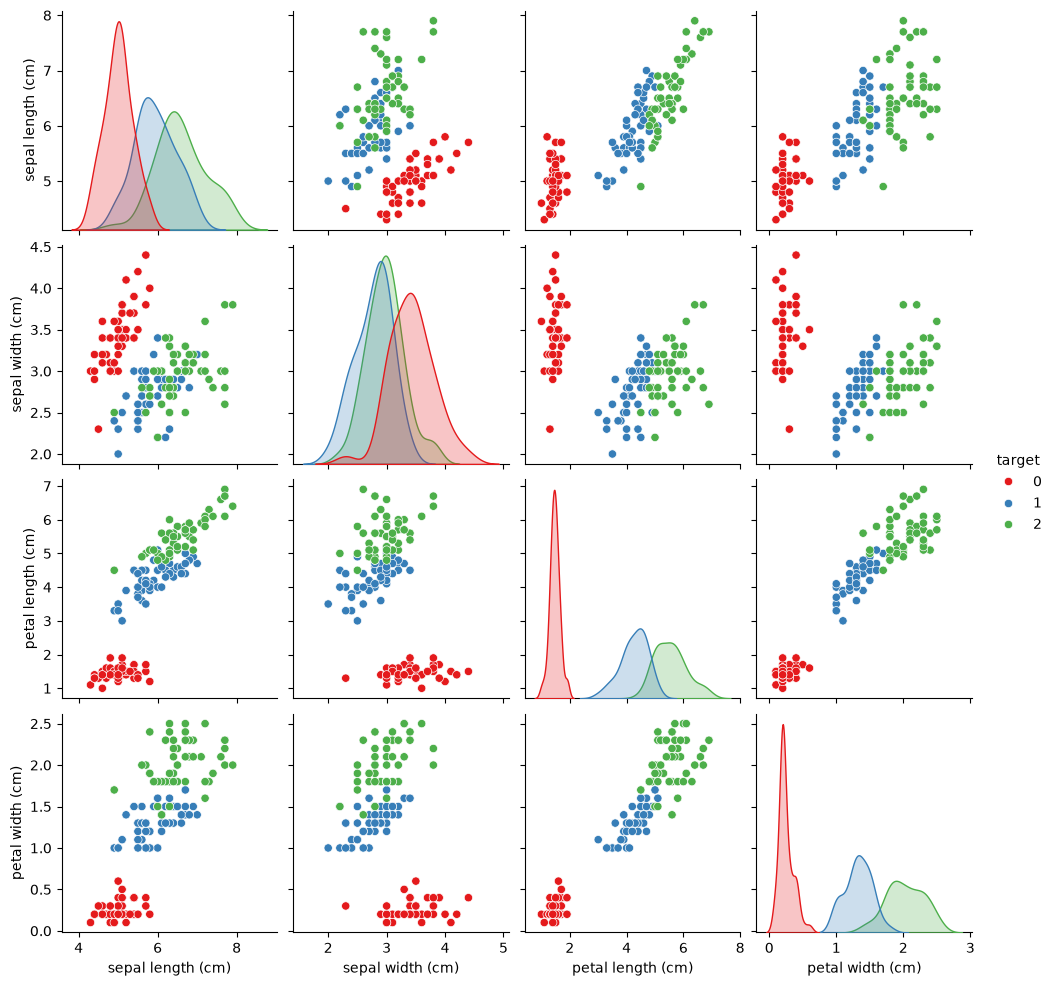

In [4]:
import seaborn as sns
sns.pairplot(data=df, hue='target', palette='Set1', diag_kind='kde')

In [5]:
df.drop(columns=['petal length (cm)','petal width (cm)'], inplace=True)

In [6]:
df.head(3)

,sepal length (cm),sepal width (cm),target
0,5.1,3.5,0
1,4.9,3.0,0
2,4.7,3.2,0


In [7]:
df=df[df['target']!=0]
df.head(3)

,sepal length (cm),sepal width (cm),target
50,7.0,3.2,1
51,6.4,3.2,1
52,6.9,3.1,1


In [8]:
x=df.iloc[:,:-1]
y=df.iloc[:,-1]
display(x.head(3))
display(y.head(3))

,sepal length (cm),sepal width (cm)
50,7.0,3.2
51,6.4,3.2
52,6.9,3.1


50    1
51    1
52    1
Name: target, dtype: int64

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score


In [10]:
lr=LogisticRegression()
knn=KNeighborsClassifier()
rf=RandomForestClassifier()
estimetors=[('lr',lr),('knn',knn),('rf',rf)]

In [11]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.8)

In [12]:
for estimetor in estimetors :
    res=cross_val_score(estimetor[1],xtrain,ytrain,cv=10,scoring='accuracy')
    print(f"model = {estimetor[0]} score = {np.round(np.mean(res),2)}")

model = lr score = 0.71
model = knn score = 0.65
model = rf score = 0.6


In [13]:
from sklearn.ensemble import VotingClassifier

In [16]:
vc=VotingClassifier(estimators=estimetors,voting='hard')
ans=cross_val_score(vc,xtest,ytest,cv=10,scoring='accuracy')
print(f"Accuracy = {np.round((np.mean(ans)),3)}")


Accuracy = 0.65


In [15]:
vc=VotingClassifier(estimators=estimetors,voting='soft',weights=[2,1,1])
ans=cross_val_score(vc,xtest,ytest,cv=10,scoring='accuracy')
print(f"Accuracy = {np.round((np.mean(ans)),3)}")

Accuracy = 0.7
